# Prediksi Pembelian Pada Perusahaan E-commernce
---

## 1. Business Understanding

### 1.1 Latar Belakang, Masalah, dan Solusi
1. **Latar Belakang**: Sebuah perusahaan e-commerce ingin menganalisis perilaku pembeli untuk mengoptimalkan kampanye pemasaran mereka. Mereka memiliki data demografi dan ekonomi pengguna beserta riwayat pembelian.
2. **Masalah**: Perusahaan kesulitan menentukan target kampanye pemasaran mereka. tanpa adanya prediksi perilaku pembeli, anggaran dana dan upaya pemasaran menjadi tidak efisien.
3. **Solusi**: Membuat model machine learning dengan menggunakan model **Naive Bayes** dengan memanfaatkan data demografi dan ekonomi pengguna beserta riwayat pembelian

### 1.2 Deskripsi Kolom Dataset **`marketing.csv`**
| Nama Kolom | Tipe Data | Keterangan |
| :-- | :-- | :-- |
| **`User ID`** | **`float64`** | Nomor identifikasi unik untuk setiap pengguna |
| **`Gender`** | **`str`** | Jenis kelamin pengguna (Male/Female) |
| **`Age`** | **`float64`** | Usia pengguna (tahun) |
| **`EstimatedSalary`** | **`float64`** | Perkiraan gaji tahunan pengguna (dalam satuan mata uang)|
| **`Purchased`** | **`float64`** | Kolom target yang menunjukkan apakah pengguna melakukan pembelian (1) atau tidak (0)|

---

## 2. Data Preparation

### 2.1 Import Library

In [28]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import tkinter as tk
from tkinter import ttk, messagebox

### 2.2 Load Dataset

In [29]:
df = pd.read_csv('marketing.csv')
df.columns = df.columns.str.strip()

### 2.3 Load Data Teratas dan Data Terbawah

In [30]:
df.head()

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510.0,Male,19.0,19000.0,0.0
1,15810944.0,Male,35.0,20000.0,0.0
2,15668575.0,Female,26.0,43000.0,0.0
3,15603246.0,Female,27.0,57000.0,0.0
4,15804002.0,Male,19.0,76000.0,0.0


In [31]:
df.tail()

,User ID,Gender,Age,EstimatedSalary,Purchased
395,15691863.0,Female,46.0,41000.0,1.0
396,15706071.0,Male,51.0,23000.0,1.0
397,15654296.0,Female,50.0,20000.0,1.0
398,15755018.0,Male,36.0,33000.0,0.0
399,15594041.0,Female,49.0,36000.0,1.0


### 2.4 Menampilkan Info Data

In [32]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   User ID          400 non-null    float64
 1   Gender           400 non-null    str    
 2   Age              400 non-null    float64
 3   EstimatedSalary  400 non-null    float64
 4   Purchased        400 non-null    float64
dtypes: float64(4), str(1)
memory usage: 15.8 KB


### 2.5 Menampilkan dan Memeriksa Dimensi Data, Jumlah Data, Missing Value, dan Data Duplikat

In [33]:
print(f'Dimensi Data: {df.shape}')
print(f'Jumlah Data: {df.size}')

print(f'\nJumlah Missing Value: {df.isnull().sum().sum()}')
print(f'==== Jumlah Missing Value Setiap Kolom ====')
print(df.isnull().sum())

print(f'\nJumlah Data Duplikat: {df.duplicated().sum()}')

Dimensi Data: (400, 5)
Jumlah Data: 2000

Jumlah Missing Value: 0
==== Jumlah Missing Value Setiap Kolom ====
User ID            0
Gender             0
Age                0
EstimatedSalary    0
Purchased          0
dtype: int64

Jumlah Data Duplikat: 0


---

## 3. Exploratory Data Analysis (EDA)

### 3.1 Menampikan Deskripsi Kolom

In [34]:
df.describe()

,User ID,Age,EstimatedSalary,Purchased
count,4.000000e+02,400.000000,400.000000,400.000000
mean,1.569154e+07,37.655000,69742.500000,0.357500
std,7.165832e+04,10.482877,34096.960282,0.479864
min,1.556669e+07,18.000000,15000.000000,0.000000
25%,1.562676e+07,29.750000,43000.000000,0.000000
50%,1.569434e+07,37.000000,70000.000000,0.000000
75%,1.575036e+07,46.000000,88000.000000,1.000000
max,1.581524e+07,60.000000,150000.000000,1.000000


### 3.2 Analisis Outlier (Metode IQR dan Z-Score)

In [35]:
outlier = []

for col in df.select_dtypes(include=np.number).columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    IQR_outliers = df[(df[col] < lower) | (df[col] > upper)]
    mean = df[col].mean()
    std = df[col].std()
    z_scores = (df[col] - mean) / std
    z_scores_outliers = df[np.abs(z_scores) > 3]

    outlier.append({
        'Kolom': col,
        'mean': mean,
        'Standarisasi': std,
        'Min': df[col].min(),
        'Q1': Q1,
        'Median': df[col].median(),
        'Q3': Q3,
        'Max': df[col].max(),
        'Batas Bawah': lower,
        'Batas Atas': upper,
        'Jumlah Outlier IQR': IQR_outliers.shape[0],
        'Jumlah Outlier Z-Score': z_scores_outliers.shape[0]
    })

pd.DataFrame(outlier)

,Kolom,mean,Standarisasi,Min,Q1,Median,Q3,Max,Batas Bawah,Batas Atas,Jumlah Outlier IQR,Jumlah Outlier Z-Score
0,User ID,1.569154e+07,71658.321581,15566689.0,15626763.75,15694341.5,15750363.0,15815236.0,1.544136e+07,1.593576e+07,0,0
1,Age,3.765500e+01,10.482877,18.0,29.75,37.0,46.0,60.0,5.375000e+00,7.037500e+01,0,0
2,EstimatedSalary,6.974250e+04,34096.960282,15000.0,43000.00,70000.0,88000.0,150000.0,-2.450000e+04,1.555000e+05,0,0
3,Purchased,3.575000e-01,0.479864,0.0,0.00,0.0,1.0,1.0,-1.500000e+00,2.500000e+00,0,0


### 3.3 Visualisasi Outlier Dengan Boxplot

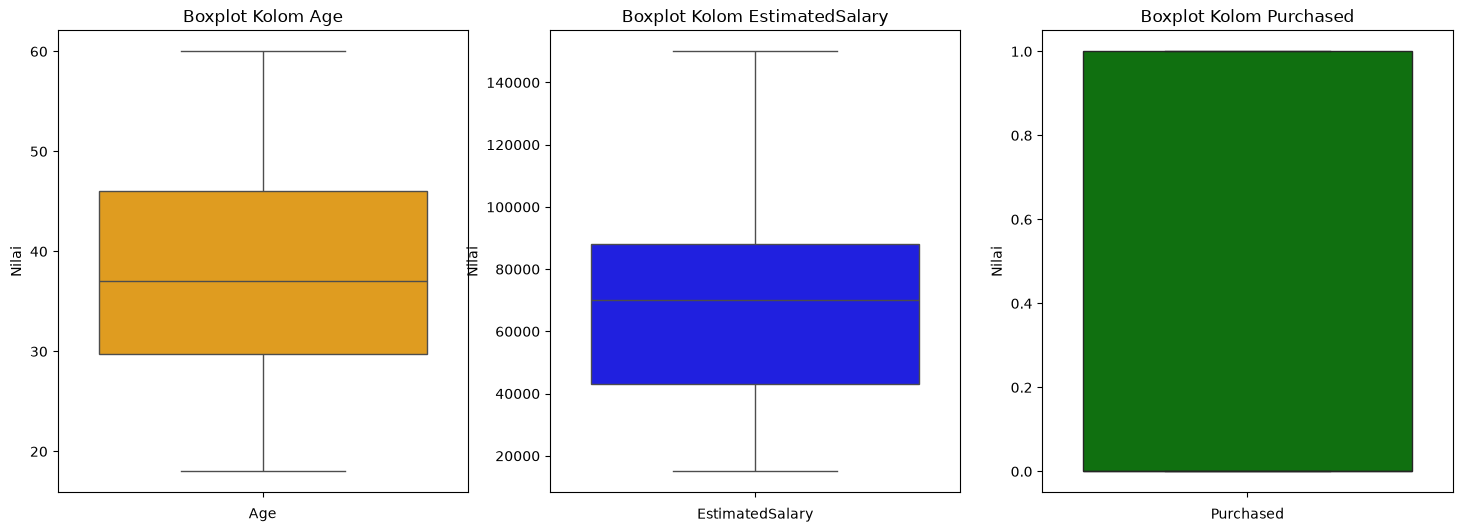

In [36]:
figure, axes = plt.subplots(1,3, figsize=(18,6))

sns.boxplot(data=df['Age'], ax=axes[0], color='orange')
axes[0].set_title('Boxplot Kolom Age')
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Nilai')

sns.boxplot(data=df['EstimatedSalary'], ax=axes[1], color='blue')
axes[1].set_title('Boxplot Kolom EstimatedSalary')
axes[1].set_xlabel('EstimatedSalary')
axes[1].set_ylabel('Nilai')

sns.boxplot(data=df['Purchased'], ax=axes[2], color='green')
axes[2].set_title('Boxplot Kolom Purchased')
axes[2].set_xlabel('Purchased')
axes[2].set_ylabel('Nilai')

plt.show()

**Insight**: Kolom **`Age`**, **`EstimatedSalary`**, dan **`Purchased`** tidak menunjukkanadanya titik outlier diluar batas IQR. Hal ini menandakan bahwa sebaran nilai berada dalam batas normal.

### 3.4 Analisis Distribusi Data

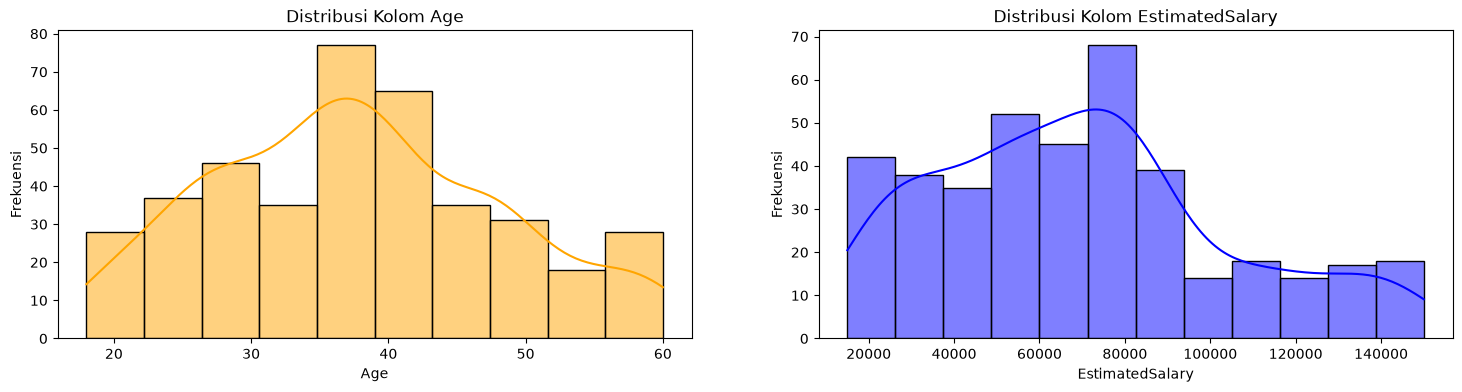

In [37]:
figure, axes = plt.subplots(1, 2, figsize=(18, 4))

sns.histplot(data=df['Age'], ax=axes[0], kde=True, color='orange')
axes[0].set_title('Distribusi Kolom Age')
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Frekuensi')

sns.histplot(data=df['EstimatedSalary'], ax=axes[1], kde=True, color='blue')
axes[1].set_title('Distribusi Kolom EstimatedSalary')
axes[1].set_xlabel('EstimatedSalary')
axes[1].set_ylabel('Frekuensi')

plt.show()

**Insight**: Pada kolom **`Age`**, distribusi data berada pada rentan normal dengan nilai rata-rata pada umur(Age) 35-40. Sedangkan pada kolom **`EstimatedSalary`**  memiliki distribusi data yang cenderung rendah pada gaji tinggi.

### 3.5 Visualisasi Distribusi Gender Berdasarkan Purchased

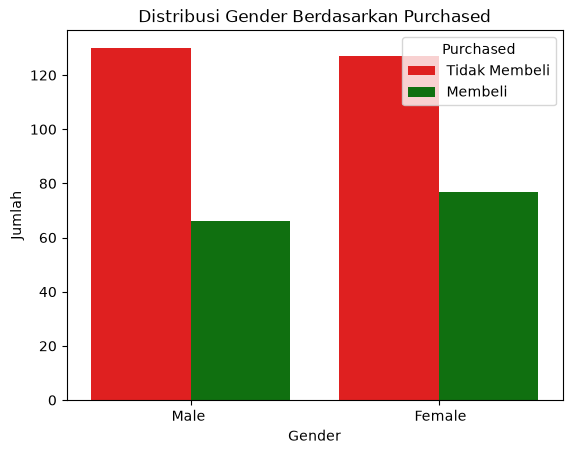

In [38]:
sns.countplot(data=df, x='Gender', palette={0: 'red', 1: 'green'}, hue='Purchased')
plt.title('Distribusi Gender Berdasarkan Purchased')
plt.xlabel('Gender')
plt.ylabel('Jumlah')
plt.legend(title='Purchased', loc='upper right', labels=['Tidak Membeli', 'Membeli'])
plt.show()

**Inight**: Pembeli perempuan(**`Female`**) sedikit lebih banyak dari pada laki-laki(**`Male`**). Namun, kedua kolom menunjukkan pola yang sama, yakni mayoritas pengguna tidak membeli.

### 3.5 Analisis Korelasi Dengan Metode Pearson, Spearman, dan Kendal 

In [39]:
var_list = ['Age', 'EstimatedSalary', 'Purchased']

korelasi = []

for i in range(len(var_list)):
    for j in range(i +1, len(var_list)):
        var1 = var_list[i]
        var2 = var_list[j]

        pearson_corr = df[var1].corr(df[var2], method='pearson')
        spearman_corr = df[var1].corr(df[var2], method='spearman')
        kendal_corr = df[var1].corr(df[var2], method='kendall')

        korelasi.append({
            'Pasangan Variabel': f'{var1} & {var2}',
            'Pearson': pearson_corr,
            'Spearman': spearman_corr,
            'Kendall': kendal_corr
        })

pd.DataFrame(korelasi)

,Pasangan Variabel,Pearson,Spearman,Kendall
0,Age & EstimatedSalary,0.155238,0.124824,0.083686
1,Age & Purchased,0.622454,0.612323,0.507788
2,EstimatedSalary & Purchased,0.362083,0.306858,0.252104


### 3.6 Visualisasi Heatmap Korelasi

Karena kolom **`Age`** dan **`EstimatedSalary`** merupakan data numerik kontinu dengan sebaran distribusi yang mendekati normal, sehingga metode pearson efektif untuk mengevaluasi hubungan linier.

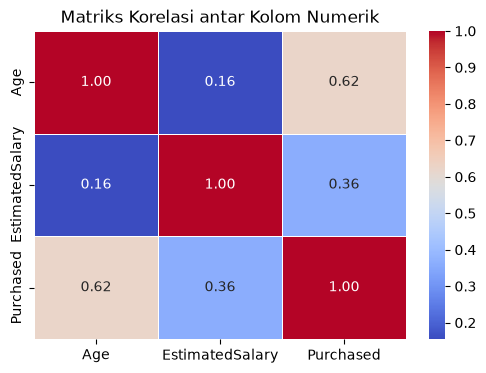

In [40]:
corr_matrix = df.drop(columns=['User ID'], errors='ignore').corr(numeric_only=True)

plt.figure(figsize=(6, 4))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Matriks Korelasi antar Kolom Numerik')
plt.show()

**Insight**: kolom fitur (**`Age`**) memiliki korelasi tertinggi dengan kolom target (**`Purchased`**) dengan nilai 0,62, diikuti oleh kolom **`EstimatedSalary`** dengan kolom **`Purchased`** dengan nilai 0,36.

### 3.7 Visualisasi Pairplot

<Figure size 1400x500 with 0 Axes>

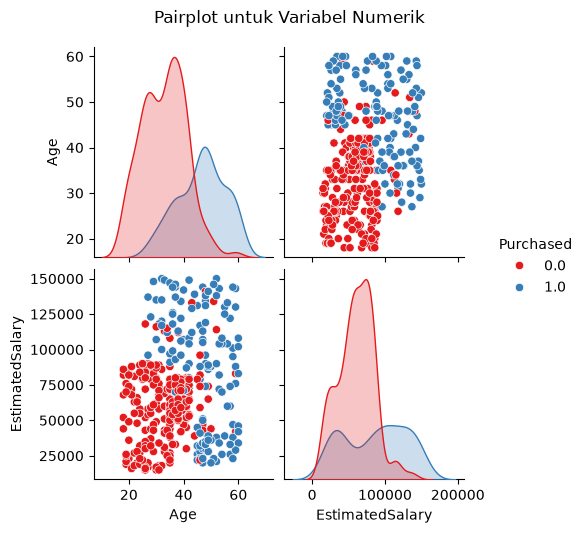

In [41]:
plt.figure(figsize=(14, 5))

sns.pairplot(df.drop(columns=['User ID'], errors='ignore'), hue='Purchased', palette='Set1')
plt.suptitle('Pairplot untuk Variabel Numerik', y=1.05)
plt.show()

**Insight**: Visualisasi pairplot menunjukkan pemisahan kelompok yang jelas di mana pengguna berusia di atas 45 tahun atau memiliki estimasi gaji di atas 100.000 didominasi oleh kelompok pembeli.

---

## 4. Data Pre-Processing

### 4.1 Memeriksa Missing Value dan Duplikat Data

In [39]:
print("Missing Value:\n", df.isnull().sum())
print("\nData Duplikat:", df.duplicated().sum())

Missing Value:
 User ID            0
Gender             0
Age                0
EstimatedSalary    0
Purchased          0
dtype: int64

Data Duplikat: 0


### 4.2 Menghapus Kolom User Id

In [40]:
data = df.drop(columns=['User ID'])
print("Kolom tersisa:", list(data.columns))

Kolom tersisa: ['Gender', 'Age', 'EstimatedSalary', 'Purchased']


### 4.3 Mengubah Kolom Gender yang Berisi Teks Menjadi Angka Biner

In [41]:
data['Gender'] = data['Gender'].str.strip().str.lower().map({'male': 1, 'female': 0})
print(data['Gender'].head())

0    1
1    1
2    0
3    0
4    1
Name: Gender, dtype: int64


### 4.4 Memisahkan Fitur ($X$) dan Target ($y$)

In [44]:
X = data[['Gender', 'Age', 'EstimatedSalary']]
y = data['Purchased'].astype(int)

print("Fitur (X) :", list(X.columns), "| Ukuran:", X.shape)
print("Target (y):", len(y), "data")

Fitur (X) : ['Gender', 'Age', 'EstimatedSalary'] | Ukuran: (400, 3)
Target (y): 400 data


### 4.5 Pembagian Data Latih dan Data Uji (80% : 20%)

In [45]:
np.random.seed(43)
acak = np.random.permutation(len(X))
batas = int(0.8 * len(X))

train_idx, test_idx = acak[:batas], acak[batas:]

X_train, X_test = X.iloc[train_idx].reset_index(drop=True), X.iloc[test_idx].reset_index(drop=True)
y_train, y_test = y.iloc[train_idx].reset_index(drop=True), y.iloc[test_idx].reset_index(drop=True)

print(f"Data Latih: {len(X_train)} baris (80%)")
print(f"Data Uji  : {len(X_test)} baris (20%)")

Data Latih: 320 baris (80%)
Data Uji  : 80 baris (20%)


---

## 5. Modelling Naive Bayes

### 5.1 Menghitung Prior Probability ($P$($y$)) & Menghitung Likelihood

In [47]:
data_0 = X_train[y_train == 0]
data_1 = X_train[y_train == 1]

prior_0 = len(data_0) / len(y_train)
prior_1 = len(data_1) / len(y_train)

mean_0 = data_0[['Age', 'EstimatedSalary']].mean()
var_0  = data_0[['Age', 'EstimatedSalary']].var()

mean_1 = data_1[['Age', 'EstimatedSalary']].mean()
var_1  = data_1[['Age', 'EstimatedSalary']].var()

p_male_0 = (data_0['Gender'] == 1).mean()
p_male_1 = (data_1['Gender'] == 1).mean()

print(f"Data Latih : {len(y_train)} baris")
print(f"Tidak Beli : {len(data_0)} orang ({prior_0:.1%})")
print(f"Beli       : {len(data_1)} orang ({prior_1:.1%})\n")

Data Latih : 320 baris
Tidak Beli : 216 orang (67.5%)
Beli       : 104 orang (32.5%)



### 5.2 Menghitung Posterior Probability

In [48]:
def gaussian(x, mean, var):
    return np.exp(-((x - mean) ** 2) / (2 * var)) / np.sqrt(2 * np.pi * var)

def hitung_posterior(gender, age, salary):
    pg_0 = p_male_0 if gender == 1 else (1 - p_male_0)
    pg_1 = p_male_1 if gender == 1 else (1 - p_male_1)

    skor_0 = prior_0 * pg_0 * gaussian(age, mean_0['Age'], var_0['Age']) * gaussian(salary, mean_0['EstimatedSalary'], var_0['EstimatedSalary'])
    skor_1 = prior_1 * pg_1 * gaussian(age, mean_1['Age'], var_1['Age']) * gaussian(salary, mean_1['EstimatedSalary'], var_1['EstimatedSalary'])
    return skor_0, skor_1

sample = X_test.iloc[0]
s0, s1 = hitung_posterior(sample['Gender'], sample['Age'], sample['EstimatedSalary'])

print(f"Contoh Data Uji : Gender={int(sample['Gender'])}, Usia={sample['Age']:.0f}, Gaji={sample['EstimatedSalary']:.0f}")
print(f"Skor Beli       : {s1}")
print(f"Skor Tidak Beli : {s0}")

Contoh Data Uji : Gender=0, Usia=34, Gaji=25000
Skor Beli       : 1.0572439390257346e-08
Skor Tidak Beli : 9.17190130472149e-08


### 5.3 Memberikan Keputusan Prediksi

In [50]:
y_pred = []

for _, row in X_test.iterrows():
    s0, s1 = hitung_posterior(row['Gender'], row['Age'], row['EstimatedSalary'])
    y_pred.append(1 if s1 > s0 else 0)

y_pred = np.array(y_pred)

print("10 Tebakan Model :", y_pred[:10])
print("10 Jawaban Asli  :", y_test.values[:10])

10 Tebakan Model : [0 0 0 0 1 1 0 0 0 0]
10 Jawaban Asli  : [0 0 0 0 1 1 0 1 0 0]


---

## 6. Evaluation

### 6.1 Membentuk Tabel Matriks Evaluasi

In [51]:
y_asli = y_test.values

TP = np.sum((y_pred == 1) & (y_asli == 1))
TN = np.sum((y_pred == 0) & (y_asli == 0))
FP = np.sum((y_pred == 1) & (y_asli == 0))
FN = np.sum((y_pred == 0) & (y_asli == 1))

tabel = pd.DataFrame(
    [[TN, FP], [FN, TP]],
    index=['Tidak Beli', 'Beli'],
    columns=['Tidak Beli', 'Beli']
)

print(f"TP: {TP} | TN: {TN} | FP: {FP} | FN: {FN}")
display(tabel)

TP: 33 | TN: 40 | FP: 1 | FN: 6


,Tidak Beli,Beli
Tidak Beli,40,1
Beli,6,33


### 6.2 Menghitung Metrik Evaluasi Klasifikasi Akurasi

In [52]:
akurasi  = (TP + TN) / len(y_asli)
presisi  = TP / (TP + FP)
recall   = TP / (TP + FN)
f1_score = 2 * presisi * recall / (presisi + recall)

print(f"Akurasi  : {akurasi:.2%}")
print(f"Presisi  : {presisi:.2%}")
print(f"Recall   : {recall:.2%}")
print(f"F1-Score : {f1_score:.2%}")

Akurasi  : 91.25%
Presisi  : 97.06%
Recall   : 84.62%
F1-Score : 90.41%


### 6.3 Visualisasi Evaluasi Model Naive Bayes: Confusion Matrix dan Performa Metriks

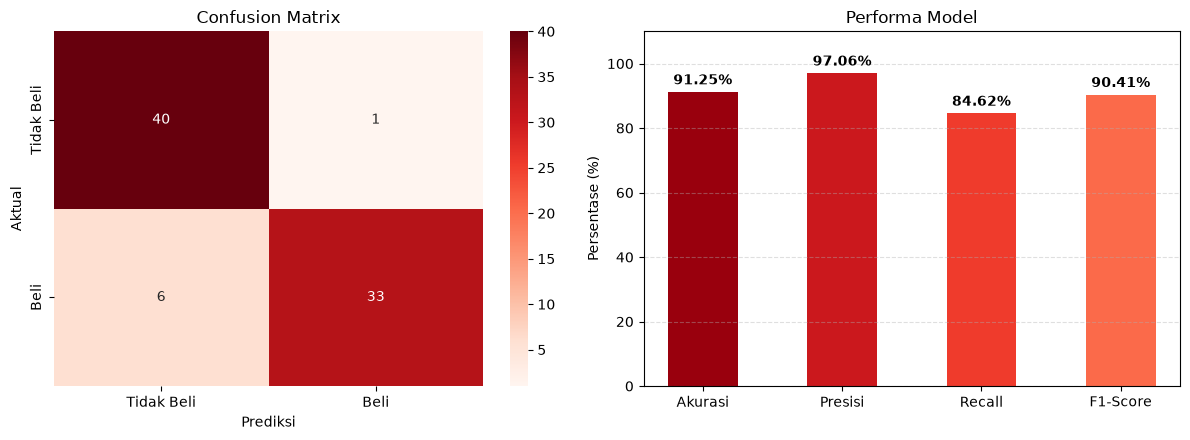

In [54]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

sns.heatmap(tabel, annot=True, fmt='d', cmap='Reds', ax=ax[0])
ax[0].set_title('Confusion Matrix')
ax[0].set_xlabel('Prediksi')
ax[0].set_ylabel('Aktual')

metrik = ['Akurasi', 'Presisi', 'Recall', 'F1-Score']
skor   = [akurasi * 100, presisi * 100, recall * 100, f1_score * 100]

bars = ax[1].bar(metrik, skor, color=['#99000d', '#cb181d', '#ef3b2c', '#fb6a4a'], width=0.5)
ax[1].bar_label(bars, fmt='%.2f%%', padding=3, fontweight='bold')
ax[1].set_ylim(0, 110)
ax[1].set_title('Performa Model')
ax[1].set_ylabel('Persentase (%)')
ax[1].grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

---

## 7. Conclusion

1. Fitur usia (`Age`) dan estimasi gaji (`EstimatedSalary`) menjadi faktor paling signifikan terhadap keputusan pembelian produk. Nasabah yang memutuskan membeli didominasi oleh kelompok usia lebih dewasa dengan pendapatan lebih tinggi, sedangkan faktor jenis kelamin (`Gender`) cenderung terdistribusi seimbang di kedua kelompok.

2. Model Naive Bayes yang dibangun menunjukkan performa yang sangat memuaskan pada data uji :
   * **Akurasi (91,25%):** Model mampu memprediksi 73 nasabah dengan benar dari total 80 data uji.
   * **Presisi (97,06%):** Dari seluruh nasabah yang diprediksi akan membeli, 33 dari 34 terbukti merupakan pembeli.
   * **Recall (84,62%):** Model berhasil menjaring 33 dari total 39 pembeli tanpa banyak kehilangan target pasar.
   * **F1-Score (90,41%):** Menunjukkan bahwa model memiliki keseimbangan yang sangat baik.

3. Dari total 80 data uji, model hanya melakukan 7 kesalahan tebak, yang didominasi oleh 6 kasus nasabah pembeli yang dikira tidak membeli. Hal ini wajar terjadi pada metode probabilistik akibat adanya perpotongan nilai pada rentang usia atau pendapatan tertentu.